In [1]:
!pip install -q medmnist gradio scikit-learn matplotlib pillow

import medmnist
from medmnist import INFO
import numpy as np
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import gradio as gr

# Load the DermaMNIST dataset
info = INFO['dermamnist']
DataClass = getattr(medmnist, info['python_class'])
labels_dict = info['label']

train_data = DataClass(split='train', download=True)
test_data = DataClass(split='test', download=True)

# Flatten 28x28 RGB images into 1D pixel arrays and normalize values between 0 and 1
X_train = train_data.imgs.reshape(len(train_data), -1) / 255.0
y_train = train_data.labels.ravel()
X_test = test_data.imgs.reshape(len(test_data), -1) / 255.0
y_test = test_data.labels.ravel()

print("Dataset loaded successfully!")
print("Classes:", labels_dict)
print(f"Training images: {len(X_train)} | Test images: {len(X_test)}")

100%|██████████| 19.7M/19.7M [00:03<00:00, 5.20MB/s]


Dataset loaded successfully!
Classes: {'0': 'actinic keratoses and intraepithelial carcinoma', '1': 'basal cell carcinoma', '2': 'benign keratosis-like lesions', '3': 'dermatofibroma', '4': 'melanoma', '5': 'melanocytic nevi', '6': 'vascular lesions'}
Training images: 7007 | Test images: 2005


Baseline Accuracy: 66.88%
Random Forest Accuracy: 71.87%


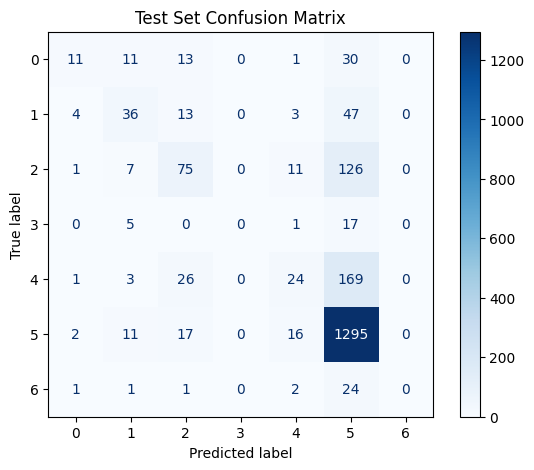

In [2]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))

# 2. Train the Random Forest Classifier (100 decision trees)
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# 3. Evaluate on unseen test images
y_pred = model.predict(X_test)
model_acc = accuracy_score(y_test, y_pred)

print(f"Baseline Accuracy: {baseline_acc:.2%}")
print(f"Random Forest Accuracy: {model_acc:.2%}")

# 4. Plot Confusion Matrix to visualize where the model succeeds and fails
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
plt.title("Test Set Confusion Matrix")
plt.show()

In [3]:
# High-risk classes in DermaMNIST: melanoma (4), basal cell carcinoma (1), actinic keratoses (0)
HIGH_RISK_CLASSES = {'0', '1', '4'}

def analyze_lesion(image, evolved_recently, bleeding_or_itching):
    if image is None:
        return "Please upload a skin lesion photo first."

    # Resize uploaded photo to 28x28 to match DermaMNIST
    img_resized = image.convert("RGB").resize((28, 28))
    img_array = np.array(img_resized).reshape(1, -1) / 255.0

    # Get model prediction & probabilities
    probs = model.predict_proba(img_array)[0]
    pred_idx = str(np.argmax(probs))
    pred_name = labels_dict[pred_idx]
    confidence = probs[int(pred_idx)] * 100

    # Original Twist: Combine AI prediction + ABCDE symptom flags for Triage Priority
    if pred_idx in HIGH_RISK_CLASSES or evolved_recently or bleeding_or_itching:
        triage = "🔴 PRIORITY: Schedule a Dermatologist Visit Soon"
        reason = "Flagged due to either a higher-risk visual pattern or active ABCDE warning symptoms."
    else:
        triage = "🟢 ROUTINE: Monitor & Mention at Next Checkup"
        reason = "Appears visually consistent with lower-risk patterns and no acute symptoms reported."

    return (
        f"### Triage Recommendation\n**{triage}**\n{reason}\n\n"
        f"---\n"
        f"**Top Visual Match:** {pred_name} ({confidence:.1f}% confidence)\n\n"
        f"⚠️ *Medical Disclaimer: This is an educational hackathon prototype, not a medical diagnosis.*"
    )

demo = gr.Interface(
    fn=analyze_lesion,
    inputs=[
        gr.Image(type="pil", label="Upload Close-Up Lesion Photo"),
        gr.Checkbox(label="Evolving: Has it changed size, shape, or color recently?"),
        gr.Checkbox(label="Symptoms: Is it bleeding, oozing, or persistently itching?")
    ],
    outputs=gr.Markdown(label="AI Triage Report"),
    title="DermaTriage AI — Educational Skin Screening Assistant",
    description="Combines computer vision (DermaMNIST) with clinical ABCDE symptom flags to help patients decide when to seek dermatology care."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://375508c72557e9f9c2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [4]:
high_risk_ids = [0, 1, 4]
actual_high_risk = np.isin(y_test, high_risk_ids)
pred_high_risk = np.isin(y_pred, high_risk_ids)

print("High-risk lesions caught:", np.sum(actual_high_risk & pred_high_risk))
print("Missed high-risk cases (false negatives):", np.sum(actual_high_risk & ~pred_high_risk))
print("False alarms (false positives):", np.sum(~actual_high_risk & pred_high_risk))

High-risk lesions caught: 94
Missed high-risk cases (false negatives): 298
False alarms (false positives): 58
